# California Housing — Doğrusal Regresyon ile Konut Değeri Tahmini
**Yüksek lisans vize çalışması | Tek model, tek notebook**

**Araştırma sorusu:** Sekiz sayısal bölge özelliği kullanılarak California'daki bir bölgenin medyan konut değeri tahmin edilebilir mi?

**Yöntem:** Çok değişkenli **Linear Regression (OLS)**. LSTM, TensorFlow, zaman serisi, alternatif modeller ve karmaşık eğitim döngüleri **yoktur**.

**Çalıştırma:** Jupyter'da `Run All` seçin. İlk çalıştırmada internet gerekir; veri bir kez indirilip `california_housing.csv` dosyasına kaydedilir. Grafikler notebook içinde görünür. İsterseniz son bölümde sonuçlar ayrıca dosyaya yazılır.

**Kurulum (terminal):** `python -m pip install notebook pandas numpy matplotlib scikit-learn` ardından `jupyter notebook`.

## 1. Kütüphaneler
- **pandas:** tablo işlemleri
- **numpy:** sayısal hesaplamalar
- **matplotlib:** grafikler
- **scikit-learn:** veri seti, eğitim/test bölme, LinearRegression ve metrikler

Burada yalnız gerekli kütüphaneleri içeri aktarıyoruz.

In [10]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error, explained_variance_score, max_error

RANDOM_STATE = 42  # Aynı train/test bölmesini yeniden üretmek için.
CSV_PATH = Path("california_housing.csv")


## 2. Veri setini indir, kaydet ve aç
California Housing: **20.640 bölge**, **8 sayısal giriş**, **1 sayısal hedef**. Bir satır tek bir ev değil, bir **nüfus sayımı bölgesi** hakkındaki toplu istatistiklerdir. Hedef `MedHouseVal`, bölgenin medyan konut değeridir ve **100.000 ABD doları** birimindedir: örneğin `2.5` yaklaşık **250.000 USD** demektir. Veriler tarihsel olup bugünün piyasa fiyatlarını temsil etmez.

CSV varsa yeniden indirilmez. Yoksa scikit-learn veriyi internetten indirir, sonra CSV kaydedilir.

In [11]:
if CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH)
    print("Yerel CSV dosyası açıldı:", CSV_PATH.resolve())
else:
    housing = fetch_california_housing(as_frame=True)
    df = housing.frame.copy()
    df.to_csv(CSV_PATH, index=False)
    print("Veri indirildi ve CSV olarak kaydedildi:", CSV_PATH.resolve())

print("Satır ve sütun sayısı:", df.shape)
display(df.head(10))


Yerel CSV dosyası açıldı: C:\Users\yucel\Desktop\Yüksek Lisans\lstm-time-series-forecasting\notebooks\california_housing.csv
Satır ve sütun sayısı: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
5,4.0368,52.0,4.761658,1.103627,413.0,2.139896,37.85,-122.25,2.697
6,3.6591,52.0,4.931907,0.951362,1094.0,2.128405,37.84,-122.25,2.992
7,3.1200,52.0,4.797527,1.061824,1157.0,1.788253,37.84,-122.25,2.414
8,2.0804,42.0,4.294118,1.117647,1206.0,2.026891,37.84,-122.26,2.267
9,3.6912,52.0,4.970588,0.990196,1551.0,2.172269,37.84,-122.25,2.611


## 3. Sütunları tanı
| Sütun | Tanım |
|---|---|
| `MedInc` | Bölgenin medyan hane geliri (veri setine özgü ölçek) |
| `HouseAge` | Bölgedeki evlerin medyan yaşı |
| `AveRooms` | Hane başına ortalama oda sayısı |
| `AveBedrms` | Hane başına ortalama yatak odası sayısı |
| `Population` | Bölgenin nüfusu |
| `AveOccup` | Hane başına ortalama kişi sayısı |
| `Latitude` | Enlem |
| `Longitude` | Boylam |
| `MedHouseVal` | **Hedef:** medyan konut değeri (100.000 USD biriminde) |

**Özellik (X):** Tahmin için kullanılan sütunlar. **Hedef (y):** Tahmin edilen sütun. `MedHouseVal` girişlere dahil edilmez.

In [12]:
print("Sütunlar:", list(df.columns))
print("Eksik değer sayısı:")
display(df.isna().sum().to_frame("Eksik"))
print("Özet istatistikler:")
display(df.describe().round(2))


Sütunlar: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
Eksik değer sayısı:


,Eksik
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


Özet istatistikler:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


## 4. Veriyi incele
Dağılım grafiği, hedef değerlerin hangi aralıklarda yoğunlaştığını gösterir. Saçılım grafiği ise medyan gelir ile konut değeri arasındaki ilişkiyi görselleştirir. **İlişki nedensellik kanıtı değildir.** Veri setinde yüksek konut değerleri üst sınırda kırpılmıştır; bu durum tahminleri etkileyebilir.

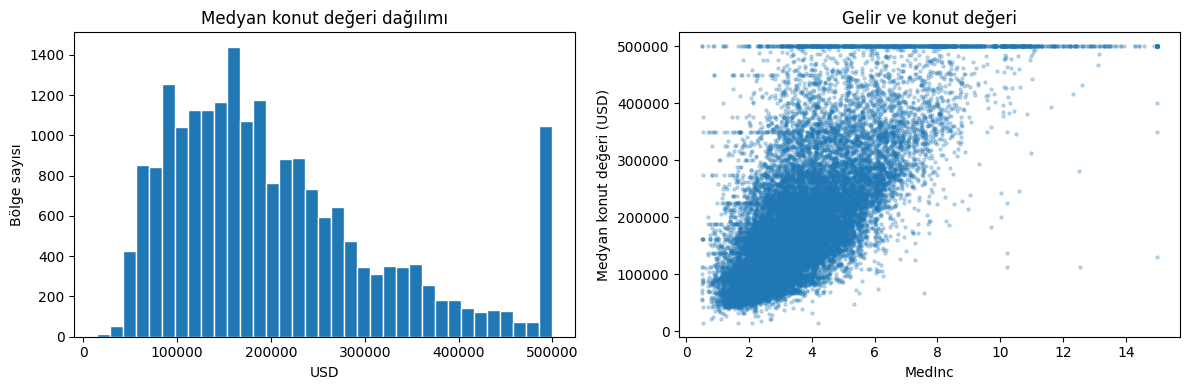

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["MedHouseVal"] * 100_000, bins=35, edgecolor="white")
axes[0].set(title="Medyan konut değeri dağılımı", xlabel="USD", ylabel="Bölge sayısı")
axes[1].scatter(df["MedInc"], df["MedHouseVal"] * 100_000, s=5, alpha=0.25)
axes[1].set(title="Gelir ve konut değeri", xlabel="MedInc", ylabel="Medyan konut değeri (USD)")
plt.tight_layout()
plt.show()


## 5. Giriş ve hedefi ayır; eğitim/test kümelerini oluştur
**Eğitim (%80):** Model katsayılarını öğrenir. **Test (%20):** Modelin görmediği örneklerde performansını ölçer. `random_state=42` aynı rastgele bölmeyi tekrar üretir. Bu çalışma **rastgele ayrılmış bölgelere** genellemeyi ölçer; yeni yıllara veya tamamen yeni coğrafyalara genelleme garantisi vermez.

Bu temel OLS modeli için `StandardScaler` **zorunlu değildir**; böylece katsayılar doğrudan orijinal sütun birimlerinde yorumlanabilir. Hedefi de ölçeklemiyoruz.

In [14]:
X = df.drop(columns="MedHouseVal")  # 8 bağımsız değişken
y = df["MedHouseVal"]               # 1 bağımlı değişken
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

# Eğitim verisindeki aykırı değerleri temizle
# Test verisine dokunmuyoruz.

Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1

alt_sinir = Q1 - 1.5 * IQR
ust_sinir = Q3 + 1.5 * IQR

# Herhangi bir sütunda sınır dışı olan satırları belirle
normal_satirlar = (
    (X_train >= alt_sinir) &
    (X_train <= ust_sinir)
).all(axis=1)

print("Temizlik öncesi:", len(X_train))

# X ve y aynı satırlardan temizlenmeli
X_train = X_train.loc[normal_satirlar]
y_train = y_train.loc[normal_satirlar]

print("Temizlik sonrası:", len(X_train))
print("Silinen satır:", (~normal_satirlar).sum())

print(f"Eğitim: {len(X_train):,} satır | Test: {len(X_test):,} satır")
print("Giriş boyutu:", X_train.shape, "| Hedef boyutu:", y_train.shape)


Temizlik öncesi: 16512
Temizlik sonrası: 13460
Silinen satır: 3052
Eğitim: 13,460 satır | Test: 4,128 satır
Giriş boyutu: (13460, 8) | Hedef boyutu: (13460,)


## 6. Tek model: Linear Regression
**Doğrusal regresyon**, girdilerin ağırlıklı toplamıyla sayısal hedefi tahmin eder:

\[\hat{y}=b+w_1x_1+w_2x_2+\cdots+w_8x_8\]

- `w`: her sütunun katsayısı (diğer sütunlar sabitken doğrusal katkı)
- `b`: sabit terim
- `fit`: eğitim verisindeki **kareli hataların toplamını** en aza indirecek katsayıları bulur (OLS)
- `predict`: öğrenilen denklemle tahmin yapar

**Önemli:** Katsayıların büyüklüklerini farklı birimlerdeki sütunlar arasında doğrudan önem sıralaması gibi yorumlamayın. Katsayılar nedensel etkiyi de kanıtlamaz.

In [15]:
model = LinearRegression()      # Tek regresyon modelini oluştur.
model.fit(X_train, y_train)    # Katsayıları yalnız eğitim verisiyle öğren.
y_pred = model.predict(X_test) # Görülmemiş test verisi için tahmin üret.

coefficients = pd.DataFrame({"Özellik": X.columns, "Katsayı": model.coef_})
print("Sabit terim (intercept):", round(float(model.intercept_), 5))
display(coefficients.round(5))


Sabit terim (intercept): -32.15468


,Özellik,Katsayı
0,MedInc,0.51157
1,HouseAge,0.01356
2,AveRooms,-0.15916
3,AveBedrms,1.82641
4,Population,0.00007
5,AveOccup,-0.43979
6,Latitude,-0.38905
7,Longitude,-0.38296


## 7. Test metrikleri — hepsi aynı model için
**MAE:** Mutlak hataların ortalaması; küçük olması iyi. **MSE:** Hataların karelerinin ortalaması; büyük hataları daha çok cezalandırır. **RMSE:** MSE'nin karekökü; hedefle aynı birimdedir. **MedAE:** Mutlak hataların ortancası. **Max Error:** En büyük mutlak hata. **R²:** Sabit test ortalaması tahminine göre karesel hata başarısı; 1 en iyi, 0 referans düzeyi, negatif de olabilir. **Explained Variance:** Açıklanan varyans skoru.

**R² bir isabet yüzdesi değildir.** MAE/RMSE/MedAE/Max Error, burada kolay yorumlanması için USD'ye çevrilir; MSE ise USD² cinsindedir. Veri setinin hedefi bölgesel medyan değeridir, tekil ev satış fiyatı değildir.

In [16]:
# Hedef 100.000 USD biriminde tutulduğu için değerlendirmede USD'ye çeviriyoruz.
y_true_usd = y_test.to_numpy() * 100_000
y_pred_usd = y_pred * 100_000
errors_usd = y_true_usd - y_pred_usd

results = {
    "MAE (USD)": mean_absolute_error(y_true_usd, y_pred_usd),
    "MSE (USD²)": mean_squared_error(y_true_usd, y_pred_usd),
    "RMSE (USD)": np.sqrt(mean_squared_error(y_true_usd, y_pred_usd)),
    "Median AE (USD)": median_absolute_error(y_true_usd, y_pred_usd),
    "Max Error (USD)": max_error(y_true_usd, y_pred_usd),
    "R²": r2_score(y_true_usd, y_pred_usd),
    "Explained Variance": explained_variance_score(y_true_usd, y_pred_usd),
}
display(pd.DataFrame({"Metrik": list(results), "Test sonucu": list(results.values())}).round(4))
print(f"Ortalama mutlak hata: ${results['MAE (USD)']:,.0f}")
print(f"R²: {results['R²']:.4f} (doğruluk yüzdesi DEĞİLDİR)")


,Metrik,Test sonucu
0,MAE (USD),5.534907e+04
1,MSE (USD²),1.452333e+10
2,RMSE (USD),1.205128e+05
3,Median AE (USD),3.915483e+04
4,Max Error (USD),4.001128e+06
5,R²,-1.083000e-01
6,Explained Variance,-1.082000e-01


Ortalama mutlak hata: $55,349
R²: -0.1083 (doğruluk yüzdesi DEĞİLDİR)


## 8. Gerçek ve tahmin grafikleri
**Sol:** İdeal durumda noktalar kesikli diyagonal üzerinde olur. **Sağ:** Artık (residual) = gerçek − tahmin. Sıfır çevresinde dağılmaları istenir. Sistematik desenler doğrusal modelin sınırlamalarını gösterebilir.

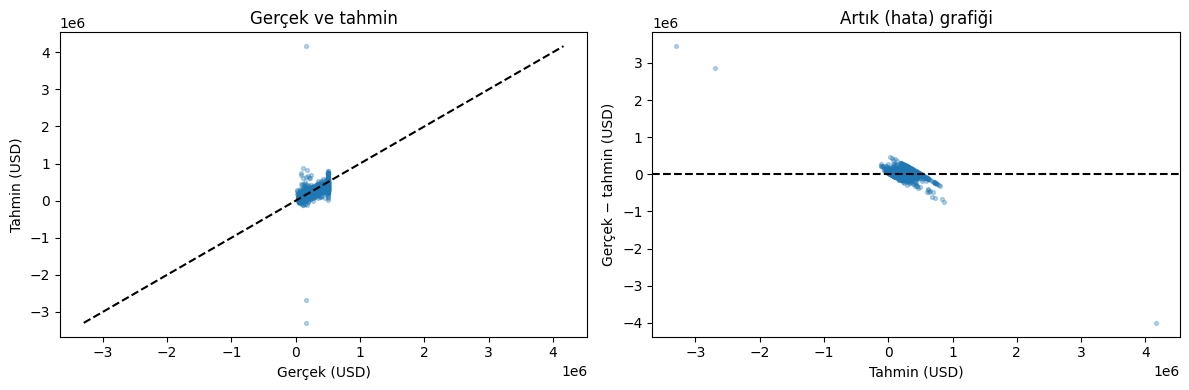

,Gerçek (USD),Tahmin (USD),Mutlak hata (USD)
0,47700.0,18801.0,28899.0
1,45800.0,193824.0,148024.0
2,500001.0,354506.0,145495.0
3,218600.0,263194.0,44594.0
4,278000.0,264831.0,13169.0
5,158700.0,207011.0,48311.0
6,198200.0,267185.0,68985.0
7,157500.0,181812.0,24312.0
8,340000.0,311578.0,28422.0
9,446600.0,418457.0,28143.0


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(y_true_usd, y_pred_usd, s=8, alpha=0.3)
lo = min(y_true_usd.min(), y_pred_usd.min())
hi = max(y_true_usd.max(), y_pred_usd.max())
axes[0].plot([lo, hi], [lo, hi], linestyle="--", color="black")
axes[0].set(title="Gerçek ve tahmin", xlabel="Gerçek (USD)", ylabel="Tahmin (USD)")
axes[1].scatter(y_pred_usd, errors_usd, s=8, alpha=0.3)
axes[1].axhline(0, linestyle="--", color="black")
axes[1].set(title="Artık (hata) grafiği", xlabel="Tahmin (USD)", ylabel="Gerçek − tahmin (USD)")
plt.tight_layout()
plt.show()

comparison = pd.DataFrame({"Gerçek (USD)": y_true_usd[:10], "Tahmin (USD)": y_pred_usd[:10],
                           "Mutlak hata (USD)": np.abs(errors_usd[:10])})
display(comparison.round(0))


## 9. Sonuçları kaydet (isteğe bağlı)
Veri `california_housing.csv` olarak zaten kaydedildi. Bu hücre ayrıca test metriklerini JSON, test tahminlerini CSV olarak kaydeder. **Eğitim, tahmin ve grafikler yine yalnız bu notebook içindedir.**

In [18]:
Path("linear_regression_metrics.json").write_text(
    json.dumps({k: float(v) for k, v in results.items()}, indent=2, ensure_ascii=False), encoding="utf-8"
)
pd.DataFrame({"actual_usd": y_true_usd, "predicted_usd": y_pred_usd,
              "error_usd": errors_usd}).to_csv("linear_regression_predictions.csv", index=False)
print("Kaydedildi: linear_regression_metrics.json ve linear_regression_predictions.csv")


Kaydedildi: linear_regression_metrics.json ve linear_regression_predictions.csv


## 10. Hocaya sunum için kısa özet
**Problem:** California'daki nüfus sayımı bölgelerinin medyan konut değerini sekiz sayısal değişkenden tahmin etmek.

**Veri:** California Housing, 20.640 gözlem, 8 girdi, 1 sürekli hedef.

**Yöntem:** Yalnız **çok değişkenli doğrusal regresyon (OLS)**. Model eğitim verisinde kareli hataları azaltan katsayıları öğrenir.

**Deney:** %80 eğitim / %20 test, sabit rastgele tohum. Test kümesi model eğitimi sırasında kullanılmaz.

**Değerlendirme:** MAE, MSE, RMSE, MedAE, Max Error, R², explained variance; gerçek-tahmin ve artık grafikleri.

**Sınırlılıklar:** Veri tarihsel ve bölge düzeyindedir; hedefte üst sınır etkisi bulunur. Doğrusal ilişki varsayımı her etkileşimi açıklamayabilir. Rastgele test bölmesi farklı coğrafya veya gelecek dönem başarısını kanıtlamaz.

**Kaynak:** [scikit-learn California Housing resmi dokümantasyonu](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_california_housing.html).